# PPO on LunarLander-v3

A Proximal Policy Optimization (PPO) agent learns to land the lunar module on its own, by trial and error.
The environment is considered solved when the agent reaches a mean score of at least 200 over 100 consecutive episodes, played without exploration.

The notebook reads from top to bottom and must run with *Restart & Run All*.

1. Setup
2. Environment
3. Random baseline
4. Actor and critic
5. Rollout storage and advantages
6. PPO update
7. Training
8. Results
9. Experiments
10. Comparison with DQN
11. Conclusion

## 1. Setup

In [115]:
import random
import time
from collections import Counter
from dataclasses import dataclass, replace
from typing import Protocol

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.distributions import Categorical


### Reproducibility

Several libraries draw random numbers in this notebook, and each one has its own generator:

| Library | Used for |
|---|---|
| `random` | the random baseline agent |
| `numpy` | shuffling and statistics helpers |
| `torch` | the initial weights of the networks and the sampling of actions from the policy |

Seeding only one of them would leave the others unpredictable, so `set_seed` fixes the three at once.
It is a function rather than three lines at the top of the notebook because section 8 trains the agent with several seeds: the generators must be reset before each run.

The environment has a generator of its own. It is seeded separately in section 2, through `env.reset(seed=...)`.

In [116]:
def set_seed(*, seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


SEED = 42
set_seed(seed=SEED)

## 2. Environment

LunarLander-v3 is a 2D landing task simulated with Box2D physics. Gymnasium takes care of the physics, the rewards and the rendering, so this notebook only deals with the agent.

The environment is created without a `render_mode`. Drawing every frame would slow training down a lot, and the agent does not need images: it only reads the observation vector. The display window is opened by `model.py` only, to watch a trained agent.

### Observations

At each step, the agent receives a vector of 8 values:

| Index | Name | Description |
|---|---|---|
| 0 | `x` | horizontal position (the landing pad is at 0, the screen edges at ±1) |
| 1 | `y` | vertical position |
| 2 | `v_x` | horizontal velocity |
| 3 | `v_y` | vertical velocity |
| 4 | `theta` | angle of the lander |
| 5 | `theta_dot` | angular velocity |
| 6 | `left_leg_contact` | 1 if the left leg touches the ground, 0 otherwise |
| 7 | `right_leg_contact` | 1 if the right leg touches the ground, 0 otherwise |

### Actions

The agent picks one of 4 discrete actions:

| Action | Effect |
|---|---|
| 0 | do nothing |
| 1 | fire the left orientation engine |
| 2 | fire the main engine |
| 3 | fire the right orientation engine |

### End of an episode

| Flag | Cause | Is there a future? |
|---|---|---|
| `terminated` | the body touched the ground (crash), the lander left the viewport, or it came to rest | no |
| `truncated` | the episode reached the limit of 1000 steps | yes, the lander could have kept going |

The two flags are kept apart everywhere in this notebook. Section 5 uses the difference: after a truncation, the critic estimates the rewards the agent would still have collected.

### Seeding and dimensions

`env.reset(seed=SEED)` seeds the environment generator once. The following resets are called without a seed and continue the same sequence, so the episodes are reproducible without replaying the same episode over and over. `env.action_space.seed(SEED)` seeds `env.action_space.sample()` in the same way.

The size of the observation and the number of actions are read from `env.observation_space` and `env.action_space` instead of being hard coded.

In [117]:
env = gym.make("LunarLander-v3")
env.action_space.seed(seed=SEED)
state, _ = env.reset(seed=SEED)
state_dim = env.observation_space.shape[0]
n_actions = env.action_space.n

print("State dimension:", state_dim)
print("Number of actions:", n_actions)

State dimension: 8
Number of actions: 4


## 3. Random baseline

Before training anything, we measure how an agent that picks its actions at random performs. This gives two things:

* **a reference score**: PPO has to beat it by far, and its learning curves will be read against it
* **a check of the evaluation tools**: the functions written in this section are reused as they are to evaluate the trained PPO agent, so a bug found here is a bug avoided later.

The section is built in three parts: the record of one episode and the reason it ended, then the random agent playing one episode, then the evaluation over 100 episodes.

### Episode result and end reason

For each episode, we will log three values: the total reward, the number of steps and why the episode ended. `EpisodeResult` groups them in a single object.

It is a `dataclass`: Python generates the constructor and the display of the object from the annotated fields, so we only declare the fields and their types. Reading `result.total_reward` is clearer than remembering that the reward is the first element of a tuple. The dataclass is `frozen`: the result of an episode is a fact, so it cannot be modified once created.

An episode ends for one of four reasons:

| Reason | Condition | Flag |
|---|---|---|
| `crash` | the body of the lander touched the ground (`env.unwrapped.game_over`) | `terminated` |
| `out_of_viewport` | the lander left the screen, `abs(x) >= 1` on the final observation | `terminated` |
| `at_rest` | the lander is not moving anymore (the only cause left) | `terminated` |
| `truncated` | the episode reached the limit of 1000 steps | `truncated` |

`env.unwrapped` gives access to the LunarLander object itself: `gym.make` wraps it in layers (such as the one that stops the episode after 1000 steps), and `game_over` is only defined on the inner object.

#### Why `abs(x) >= 1` means the lander left the screen

The `x` of the observation is not a raw coordinate. The screen is 600 pixels wide and Box2D uses 1 unit for 30 pixels, so the physics world is 20 units wide, with the landing pad at 10. Before building the observation, Gymnasium normalizes the position:

$$x = \frac{x_{\text{raw}} - 10}{10}$$

Subtracting 10 puts the landing pad at 0, and dividing by the half width puts the screen edges at ±1:

| Raw position | Normalized `x` | Where the lander is |
|---|---|---|
| 0 | −1 | left edge |
| 10 | 0 | above the landing pad |
| 20 | +1 | right edge |

`abs` removes the sign and keeps the distance to the center, so `abs(x) >= 1` covers both edges in one test. This is the exact condition Gymnasium uses to terminate the episode, which is why the detection reads the final observation instead of the raw position of the lander. The threshold is stored in `VIEWPORT_X_LIMIT`.

The vertical position follows the same idea: `y = 0` when the legs are at the height of the landing pad, and the lander starts around `y = 1.4`, at the top of the screen. Keeping every value of the observation around [−1.5, 1.5] also helps the neural networks, which learn poorly when their inputs have very different scales.

The order of the tests matters. A crash can throw the lander out of the screen in the same step, and that episode must count as a crash, its real cause. `at_rest` is never tested directly: it is what remains once the other causes of termination are excluded.

The four reasons are defined once as constants. Every part of the notebook uses these constants instead of typing the strings again, so a typo cannot create a fifth reason.

This detection is a function of its own because two places need it: `run_episode` below, and the training loop of section 7, which logs the end reason of every training episode.

In [118]:
CRASH = "crash"
OUT_OF_VIEWPORT = "out_of_viewport"
AT_REST = "at_rest"
TRUNCATED = "truncated"
END_REASONS = (CRASH, OUT_OF_VIEWPORT, AT_REST, TRUNCATED)

VIEWPORT_X_LIMIT = 1.0


@dataclass(frozen=True)
class EpisodeResult:
    total_reward: float
    n_steps: int
    end_reason: str


def get_end_reason(*, env: gym.Env, final_state: np.ndarray, terminated: bool) -> str:
    if not terminated:
        return TRUNCATED
    if env.unwrapped.game_over:
        return CRASH
    x_position = final_state[0]
    if abs(x_position) >= VIEWPORT_X_LIMIT:
        return OUT_OF_VIEWPORT
    return AT_REST

### Random agent

In this notebook, an **agent** is anything that receives the current observation by name (`state=`) and returns an action as an `int`. `run_episode` never knows which agent it plays: the random agent now, the trained PPO agent in section 8. This is what makes the same evaluation code usable for both.

This contract is written as a `Protocol` named `Agent`. A `Protocol` describes the shape an object must have, without any inheritance: every function whose signature is `(*, state: np.ndarray) -> int` is a valid `Agent`. The simpler type `Callable[..., int]` would accept any function returning an `int`, but it cannot express that `state` must be passed by name.

The random agent ignores the observation and draws one of the 4 actions with `env.action_space.sample()`. This is the generator seeded in section 2, so the baseline is reproducible. It still receives `state`, only to match the `Agent` contract: its name is imposed by the call `agent(state=state)`.

`sample()` returns a NumPy integer, which is converted to a Python `int` to respect the return type.

In [119]:
class Agent(Protocol):
    def __call__(self, *, state: np.ndarray) -> int: ...


def random_agent(*, state: np.ndarray) -> int:
    return int(env.action_space.sample())

### Playing one episode

`run_episode` plays one full episode with any agent and returns its `EpisodeResult`:

1. `env.reset()` starts the episode and returns the initial observation.
2. At each step, the agent picks an action from the current observation, and `env.step(action)` advances the physics by 1/50 of a second. It returns the next observation, the reward of this step, `terminated` and `truncated`.
3. The reward is added to the total and the step is counted.
4. When `terminated` or `truncated` is true, the episode is over: `get_end_reason` finds the cause and the result is returned.
5. Otherwise, the next observation becomes the current one and the loop goes on.

Two observations exist when the episode ends: `state`, from which the last action was chosen, and `next_state`, returned by the last `env.step`. Gymnasium tests the end conditions on `next_state`, so this is the one given to `get_end_reason`. With `state`, a lander leaving the screen on its last step would be counted as `at_rest`.

`env.reset()` is called without a seed. The environment was seeded once in section 2, and each reset continues that sequence: the episodes are reproducible, but they are all different. Passing the seed at every reset would replay the same episode over and over.

The rewards returned by Gymnasium are NumPy floats, so the total is converted to a Python `float` to match the annotation of `EpisodeResult`.

In [120]:
def run_episode(*, env: gym.Env, agent: Agent) -> EpisodeResult:
    state, _ = env.reset()
    total_reward = 0.0
    n_steps = 0

    while True:
        action = agent(state=state)
        next_state, reward, terminated, truncated, _ = env.step(action)
        total_reward += reward
        n_steps += 1

        if terminated or truncated:
            return EpisodeResult(
                total_reward=float(total_reward),
                n_steps=n_steps,
                end_reason=get_end_reason(env=env, final_state=next_state, terminated=terminated),
            )

        state = next_state


print(run_episode(env=env, agent=random_agent))

EpisodeResult(total_reward=-108.55402945184308, n_steps=106, end_reason='crash')


### Evaluation over 100 episodes

The subject measures an agent over **100 consecutive episodes**, played without exploration: the environment is solved when the mean score reaches at least 200. The baseline uses the same protocol, so that every score of this notebook is measured the same way.

A single episode says little: the starting push of the lander is random, so the same agent can crash in one episode and land in the next. Over 100 episodes, three measures describe the agent:

| Measure | What it tells |
|---|---|
| **mean reward** | how good the agent is on average, compared with the threshold of 200 |
| **standard deviation** | how regular it is: a low value means the agent behaves the same way in every episode, a high value means its results swing between good and bad episodes |
| **distribution** (histogram) | the shape behind the mean: a mean of 150 can hide many landings and a few heavy crashes |

The **end reasons** complete the picture. They tell how the agent fails: crashing, leaving the screen or hovering until the time limit are three different problems to fix. The four reasons are always reported, with 0 when a reason never happens, so that the tables of the random, PPO and DQN agents can be compared line by line.

The evaluation is split into three functions, each with one job:

1. `evaluate` plays the episodes and returns the raw `EpisodeResult` of each one;
2. `summarize_results` computes the statistics from these results, without playing or displaying anything, and returns them in an `EvaluationSummary`;
3. `plot_reward_distribution` draws the histogram of the scores, with the mean and the threshold of 200 as vertical lines.

Keeping the raw results separate from the statistics allows reusing them: section 8 evaluates the final PPO agent with the same functions, and section 10 puts the summaries of the random, PPO and DQN agents side by side.

In [121]:
SOLVED_THRESHOLD = 200.0


def evaluate(*, env: gym.Env, agent: Agent, n_episodes: int) -> list[EpisodeResult]:
    return [run_episode(env=env, agent=agent) for _ in range(n_episodes)]


@dataclass(frozen=True)
class EvaluationSummary:
    mean_reward: float
    std_reward: float
    mean_steps: float
    end_reasons: dict[str, int]


def summarize_results(*, results: list[EpisodeResult]) -> EvaluationSummary:
    rewards = [result.total_reward for result in results]
    steps = [result.n_steps for result in results]
    end_reason_counts = Counter(result.end_reason for result in results)
    return EvaluationSummary(
        mean_reward=float(np.mean(rewards)),
        std_reward=float(np.std(rewards)),
        mean_steps=float(np.mean(steps)),
        end_reasons={reason: end_reason_counts[reason] for reason in END_REASONS},
    )


def plot_reward_distribution(*, results: list[EpisodeResult], title: str) -> None:
    rewards = [result.total_reward for result in results]
    plt.hist(rewards, bins=20)
    plt.axvline(np.mean(rewards), color="red", linestyle="--", label="mean")
    plt.axvline(SOLVED_THRESHOLD, color="green", linestyle=":", label=f"solved ({SOLVED_THRESHOLD:.0f})")
    plt.xlabel("Total reward per episode")
    plt.ylabel("Number of episodes")
    plt.title(title)
    plt.legend()
    plt.show()

Random agent over 100 episodes
Mean reward: -177.2 ± 94.6
Mean steps:  93.9
End reasons: {'crash': 95, 'out_of_viewport': 5, 'at_rest': 0, 'truncated': 0}


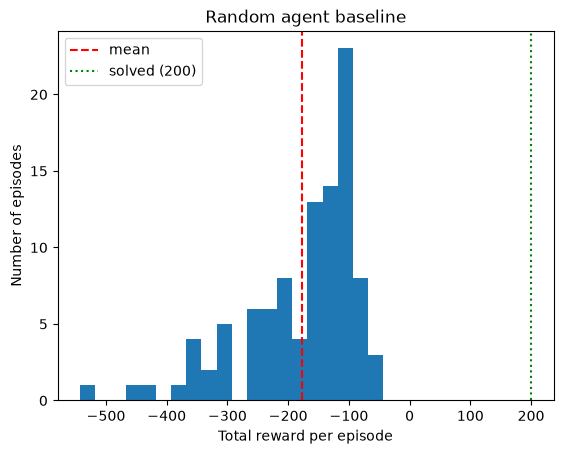

In [122]:
N_EVAL_EPISODES = 100

baseline_results = evaluate(env=env, agent=random_agent, n_episodes=N_EVAL_EPISODES)
baseline_summary = summarize_results(results=baseline_results)

print(f"Random agent over {N_EVAL_EPISODES} episodes")
print(f"Mean reward: {baseline_summary.mean_reward:.1f} ± {baseline_summary.std_reward:.1f}")
print(f"Mean steps:  {baseline_summary.mean_steps:.1f}")
print(f"End reasons: {baseline_summary.end_reasons}")

plot_reward_distribution(results=baseline_results, title="Random agent baseline")

### Baseline results

| Measure | Random agent |
|---|---|
| mean reward | −177.2 |
| standard deviation | 94.6 |
| median reward | −143.8 |
| best / worst episode | −43.4 / −542.5 |
| mean episode length | 93.9 steps (about 2 seconds) |
| end reasons | 95 crashes, 5 out of viewport, 0 at rest, 0 truncated |

* **No episode is positive.** The best one scores −43.4, and the mean is about 377 points below the threshold of 200: this is the gap PPO has to close.
* **The random agent almost always crashes, and quickly.** With no control, the lander falls nearly freely and hits the ground in about 2 seconds of simulation. It never lands (0 at rest) and never lasts until the time limit (0 truncated).
* **The distribution is asymmetric.** Half of the episodes (51) lie between −150 and −50, but a long tail goes down to −542.5 (14 episodes below −300), which pulls the mean below the median. The lowest scores come from episodes where random engine firings move the lander away from the pad or push it faster into the ground: these are penalized step after step, and the fuel spent costs points too.
* **The DQN notebook measured a close baseline** (−173.4 ± 110.0, 93 crashes and 7 out of viewport). The values differ slightly because its random agent uses another generator (`random.randrange`), but both describe the same behavior.

These results also give a first idea of what the learning curves should show: the agent must first stop crashing (more truncated episodes, while it learns to hover), then learn to land (at rest episodes appear, and the mean score goes above 0, then above 200).

## 4. Actor and critic

PPO learns with two neural networks that have different jobs:

| Network | Question it answers | Input | Output |
|---|---|---|---|
| **actor** | what should the lander do in this situation? | the observation (8 values) | one probability per action (4 values summing to 1): the **policy** |
| **critic** | how good is this situation? | the observation (8 values) | one value $V(s)$: the total reward the agent can still expect from this state by following its current policy |

During training, the action is **sampled** from the probabilities of the actor: an action with a probability of 0.85 is chosen most of the time, but not always. This is how PPO explores, with no epsilon-greedy. During evaluation, the agent stops exploring and always takes the most probable action.

The critic never chooses anything. It is a reference for the actor: after an action, comparing what really happened with what the critic expected tells whether the action was better or worse than usual (section 5). The actor then makes the good actions more likely and the bad ones less likely (section 6).

### Two separate networks

The subject allows one network with two outputs (two "heads" on a shared body) or two separate networks. This notebook uses **two separate networks**:

* **The two trainings do not interfere.** With a shared body, the loss of the actor and the loss of the critic update the same weights, and their coefficients must be balanced carefully so that one does not overwrite the other. With separate networks, each one only learns its own task.
* **It is the default of the reference implementations** for observations given as vectors (Stable-Baselines3, CleanRL).
* **The cost is negligible**: each network has a few thousand weights.

A shared body mostly pays off when the input is an image: the layers that "understand" the image are expensive, and sharing them saves a lot of computation. With 8 numbers as input, there is nothing worth sharing.

### Configuration

All the hyperparameters of PPO live in a single `PPOConfig`. It is defined once, here, and starts with the size of the networks. The following sections add their own fields to this same class and explain each value in the section that uses it.

`PPOConfig` is a frozen `dataclass` rather than a dictionary:

* **A typo is an immediate error.** `config.hiden_size` raises an `AttributeError`, while `CONFIG["hiden_size"]` is only noticed when the line runs.
* **Every field has a type and a default value**, so `PPOConfig()` is the reference configuration.
* **The configuration cannot change by accident during training**, since it is frozen. An experiment creates a modified copy instead: `replace(config, hidden_size=128)` changes one field and leaves the reference untouched. This is the method of section 9, where one hyperparameter changes at a time.

| Field | Value | Reason |
|---|---|---|
| `hidden_size` | 64 | number of neurons in each of the two hidden layers of the actor and of the critic. 64 is the standard size for PPO on small vector observations (Stable-Baselines3, CleanRL), and it is enough to map 8 inputs to 4 outputs. The DQN notebook uses 128, and section 9 can compare both sizes. |

In [123]:
@dataclass(frozen=True)
class PPOConfig:
    hidden_size: int = 64
    n_steps: int = 2048
    gamma: float = 0.99
    gae_lambda: float = 0.95
    learning_rate: float = 3e-4
    n_epochs: int = 10
    batch_size: int = 64
    clip_range: float = 0.2
    entropy_coef: float = 0.01
    max_grad_norm: float = 0.5


config = PPOConfig()
print("Config:", config)


Config: PPOConfig(hidden_size=64, n_steps=2048, gamma=0.99, gae_lambda=0.95)


### Building the networks

The actor and the critic share the same architecture: only the size of the output and one setting of the initialization differ. A single function, `build_mlp`, builds both.

```
                 ┌─ Linear(8, 64) ─ Tanh ─ Linear(64, 64) ─ Tanh ─ Linear(64, 4) ─► 4 logits   actor
observation (8) ─┤
                 └─ Linear(8, 64) ─ Tanh ─ Linear(64, 64) ─ Tanh ─ Linear(64, 1) ─► V(s)       critic
```

An MLP (multi-layer perceptron) is a sequence of `Linear` layers separated by activation functions. `build_mlp` returns an `nn.Sequential`: it is already a complete PyTorch module, whose forward pass runs the layers in order, so no custom class with a `forward` method is needed.

The layers between the input and the output are called **hidden layers**: their values stay inside the network and nobody reads them, unlike the input (the observation) and the output (the logits or $V(s)$). Each network here has two hidden layers of `hidden_size` = 64 neurons: the outputs of `Linear(8, 64)` and of `Linear(64, 64)`, each followed by `Tanh`. The last `Linear` is the **output layer**.

#### Tanh instead of ReLU

The DQN notebook uses `ReLU`. For PPO, `Tanh` is the standard choice (default of Stable-Baselines3 and CleanRL):

* `Tanh` squashes its outputs between −1 and 1, so the values inside the network stay bounded;
* the policy changes more smoothly from one update to the next, which is exactly what PPO tries to enforce;
* the large scale study of Andrychowicz et al. (2021, *What Matters in On-Policy Reinforcement Learning?*) found `Tanh` to work better than `ReLU` for PPO.

#### The actor outputs logits

The 4 outputs of the actor are **logits**: unbounded numbers, one per action, where a larger logit means a more likely action. The network has no `Softmax` at the end. In the next step, `Categorical(logits=...)` turns them into probabilities and computes the log probabilities in a numerically stable way. Computing `log(softmax(x))` in two separate steps can produce `log(0) = -inf` when a probability becomes tiny.

#### Orthogonal initialization

When a `Linear` layer is created, PyTorch already fills its weights and biases with random values (a uniform distribution whose range only depends on the number of inputs). These defaults are generic: they do not know that the network is a policy trained with PPO. The reference implementations replace them with an **orthogonal** initialization and a **gain** (a scale factor) chosen for each layer, for three reasons:

* **The actor must start with no preference.** At the start, the agent knows nothing, so it should try the 4 actions equally. With the default weights, the initial logits are not close to 0, and the actor can prefer one action in every state only because of the random draw. In one test draw, the default actor gave the probabilities 25.6%, 28.8%, 21.8% and 23.8% to the first observation, and the second action was the most likely in every tested state. With an output gain of 0.01, the logits are almost 0 and every probability is about 25%.
* **The signal must not fade from one layer to the next.** Each layer multiplies its inputs by its weights. If the weights are too small, the values shrink at every layer, and the last layers receive almost nothing to learn from. In a test with 10 `Tanh` layers of 64 neurons, the spread (standard deviation) of the values dropped from 0.46 to 0.09 with the default weights, and stayed around 0.56 with orthogonal weights and a gain of $\sqrt{2}$. An orthogonal matrix preserves the length of the vectors it multiplies, and the gain compensates for the squashing of `Tanh`. With two hidden layers only, the effect is smaller here, but the principle is the same.
* **No neuron should start with a random offset.** The default biases are random too, so each neuron is pushed in an arbitrary direction before seeing any observation. With biases at 0, only the weights decide at the start, and training adjusts the biases where they are useful.

| Layers | Gain | Reason |
|---|---|---|
| hidden layers | $\sqrt{2}$ | keeps the scale of the signal roughly constant from one layer to the next |
| output of the **actor** | 0.01 | the initial logits are almost 0, so the initial policy is almost uniform (about 25% per action): the agent starts with no preference and explores as much as possible |
| output of the **critic** | 1 | initial values on a normal scale, so the first errors of the critic stay moderate |
| all biases | 0 | no initial offset |

The default initialization would still train: it is not a bug, only a worse start. The large scale study of Andrychowicz et al. (2021) found that a small last layer for the actor is one of the choices that matter most for PPO, and orthogonal initialization is one of *The 37 Implementation Details of Proximal Policy Optimization* (Huang et al., 2022).

The three gains are constants rather than fields of `PPOConfig`: they are standard implementation choices, not hyperparameters that this notebook tunes.

In [124]:
HIDDEN_GAIN = np.sqrt(2)
ACTOR_OUTPUT_GAIN = 0.01
CRITIC_OUTPUT_GAIN = 1.0


def initialize_layer(*, layer: nn.Linear, gain: float) -> None:
    nn.init.orthogonal_(layer.weight, gain=gain)
    nn.init.zeros_(layer.bias)


def build_mlp(*, input_size: int, hidden_size: int, output_size: int, output_gain: float) -> nn.Sequential:
    input_layer = nn.Linear(input_size, hidden_size)
    hidden_layer = nn.Linear(hidden_size, hidden_size)
    output_layer = nn.Linear(hidden_size, output_size)

    initialize_layer(layer=input_layer, gain=HIDDEN_GAIN)
    initialize_layer(layer=hidden_layer, gain=HIDDEN_GAIN)
    initialize_layer(layer=output_layer, gain=output_gain)

    return nn.Sequential(input_layer, nn.Tanh(), hidden_layer, nn.Tanh(), output_layer)

The two networks are built from the environment dimensions and the configuration, then checked:

* the number of weights: $8 \times 64 + 64 = 576$, then $64 \times 64 + 64 = 4160$, then $64 \times 4 + 4 = 260$ for the actor (4996 in total), and $64 \times 1 + 1 = 65$ for the last layer of the critic (4801 in total);
* the initial policy on the first observation, which should be close to uniform thanks to the small output gain of the actor;
* the output shapes for a single observation and for a batch of 32 observations: training processes many observations at once, so both cases must work.

In [125]:
TEST_BATCH_SIZE = 32

actor = build_mlp(
    input_size=state_dim,
    hidden_size=config.hidden_size,
    output_size=n_actions,
    output_gain=ACTOR_OUTPUT_GAIN,
)
critic = build_mlp(
    input_size=state_dim,
    hidden_size=config.hidden_size,
    output_size=1,
    output_gain=CRITIC_OUTPUT_GAIN,
)
print(actor)
print(critic)


def count_parameters(*, network: nn.Module) -> int:
    return sum(parameter.numel() for parameter in network.parameters())


print("Actor parameters:", count_parameters(network=actor))
print("Critic parameters:", count_parameters(network=critic))

state_tensor = torch.as_tensor(state, dtype=torch.float32)
batch = torch.zeros(TEST_BATCH_SIZE, state_dim)

with torch.no_grad():
    initial_policy = torch.softmax(actor(state_tensor), dim=-1)
    print("Initial policy:", initial_policy)
    print("Single state:", actor(state_tensor).shape, critic(state_tensor).shape)
    print("Batch:", actor(batch).shape, critic(batch).shape)

Sequential(
  (0): Linear(in_features=8, out_features=64, bias=True)
  (1): Tanh()
  (2): Linear(in_features=64, out_features=64, bias=True)
  (3): Tanh()
  (4): Linear(in_features=64, out_features=4, bias=True)
)
Sequential(
  (0): Linear(in_features=8, out_features=64, bias=True)
  (1): Tanh()
  (2): Linear(in_features=64, out_features=64, bias=True)
  (3): Tanh()
  (4): Linear(in_features=64, out_features=1, bias=True)
)
Actor parameters: 4996
Critic parameters: 4801
Initial policy: tensor([0.2500, 0.2500, 0.2504, 0.2496])
Single state: torch.Size([4]) torch.Size([1])
Batch: torch.Size([32, 4]) torch.Size([32, 1])


### Network checks

| Check | Result | Expected |
|---|---|---|
| parameters of the actor | 4996 | $576 + 4160 + 260 = 4996$ |
| parameters of the critic | 4801 | $576 + 4160 + 65 = 4801$ |
| initial policy | 0.2500, 0.2500, 0.2504, 0.2496 | about 0.25 per action |
| shapes for one observation | actor `[4]`, critic `[1]` | 4 logits, 1 value |
| shapes for a batch of 32 | actor `[32, 4]`, critic `[32, 1]` | one row per observation |

**The architecture is correct.** The printed modules follow the diagram above, and the parameter counts match the sizes of the layers exactly. A parameter is one adjustable number of the network (a weight or a bias): these few thousand numbers are everything the networks know, and training will only adjust them. A mistake in the size of a layer would change these totals.

**The initial policy is uniform.** The first observation of the episode (lander near the center, high above the pad, legs off the ground) gives 4 logits of about $10^{-3}$, because of the output gain of 0.01. The softmax of 4 almost equal numbers is almost 25% for each action, and the largest gap is 0.04%. The actor starts with no preference: during the first rollouts, it samples the 4 actions equally, which is the most exploring behavior possible. The probabilities only move away from 25% once the PPO update starts to favor the actions with a positive advantage.

**The critic knows nothing yet.** Its output on the same observation is about $-0.1$, a value on a normal scale but with no meaning: the critic is not trained. A trained critic would give a large positive value to a state that leads to a landing and a negative value to a state that leads to a crash.

**Batches work without any change.** Given 32 observations at once, the networks return one output row per observation. `nn.Linear` applies the same weights to every row of its input in a single matrix product, with no Python loop. Training relies on this: the critic evaluates every state of a rollout in one call, and the PPO update processes minibatches of observations.

The networks are ready but untrained. The next step uses them to choose actions: sampling an action from the probabilities of the actor, and keeping its log probability and the value of the critic for the update.

### Choosing an action

During training, at every step of the game, the agent needs three things from the two networks:

1. **an action**, sampled from the probabilities of the actor. Sampling instead of always taking the most probable action is how PPO explores;
2. **the log probability of that action**, stored as the "old" probability. The PPO update compares it with the probability given by the updated actor (section 6);
3. **the value $V(s)$ of the state**, given by the critic. It is needed to compute the advantages (section 5).

`sample_action` computes the three at once and returns them in an `ActionSample`, a frozen dataclass like `EpisodeResult`: `sample.log_prob` is clearer than the second element of a tuple.

| Step | What happens | Example on the first observation |
|---|---|---|
| `actor(states)` | the actor outputs 4 logits | about $10^{-3}$ each |
| `Categorical(logits=...)` | builds a distribution over the 4 actions, with the probabilities given by the softmax of the logits | about 25% each |
| `distribution.sample()` | draws one action from this distribution | for example 2 (main engine) |
| `distribution.log_prob(action)` | the logarithm of the probability of the drawn action | $\log(0.25) \approx -1.386$ |
| `critic(states).squeeze(-1)` | the value of the state, without the last dimension of size 1 | about $-0.1$ |

#### Why `Categorical`

`torch.distributions.Categorical` gathers everything PPO needs about a discrete policy: sampling, log probabilities, and later the entropy used as an exploration bonus. It works on a single observation as well as on a batch, with no Python loop. Building it from `logits` rather than from probabilities lets PyTorch compute the log probabilities in a numerically stable way.

#### Why the log probability

The PPO update measures how much the policy changed with the ratio $\frac{\pi_{new}(a \mid s)}{\pi_{old}(a \mid s)}$, computed as $\exp(\log \pi_{new} - \log \pi_{old})$. Subtracting logarithms stays precise even when a probability becomes tiny, while dividing two tiny probabilities loses precision.

#### Why `torch.no_grad`

While playing, the agent collects data and does not learn. The stored log probabilities and values are fixed references for the update: they must not change when the networks are updated. The `@torch.no_grad()` decorator tells PyTorch not to record the computations for gradients, which saves memory and time and guarantees that the stored tensors are plain constants.

#### Checks

* on the first observation: an action between 0 and 3, a log probability close to $\log(0.25)$, and the value of the previous checks;
* on a batch of 32 observations: three tensors of shape `[32]`, one entry per observation;
* on 10,000 draws from the same observation: each action is drawn about 2,500 times, so the sampling follows the probabilities of the actor.

In [126]:
@dataclass(frozen=True)
class ActionSample:
    action: torch.Tensor
    log_prob: torch.Tensor
    value: torch.Tensor


@torch.no_grad()
def sample_action(*, actor: nn.Module, critic: nn.Module, states: torch.Tensor) -> ActionSample:
    distribution = Categorical(logits=actor(states))
    action = distribution.sample()
    return ActionSample(
        action=action,
        log_prob=distribution.log_prob(action),
        value=critic(states).squeeze(-1),
    )

In [127]:
N_SAMPLING_CHECKS = 10_000

single_sample = sample_action(actor=actor, critic=critic, states=state_tensor)
print("Single state:", single_sample)

batch_sample = sample_action(actor=actor, critic=critic, states=batch)
print("Batch shapes:", batch_sample.action.shape, batch_sample.log_prob.shape, batch_sample.value.shape)

repeated_states = state_tensor.repeat(N_SAMPLING_CHECKS, 1)
repeated_sample = sample_action(actor=actor, critic=critic, states=repeated_states)
print("Action counts:", torch.bincount(repeated_sample.action, minlength=n_actions))

Single state: ActionSample(action=tensor(3), log_prob=tensor(-1.3881), value=tensor(-0.1026))
Batch shapes: torch.Size([32]) torch.Size([32]) torch.Size([32])
Action counts: tensor([2510, 2487, 2473, 2530])


### Sampling checks

| Check | Result | Expected |
|---|---|---|
| action on the first observation | 3 (right engine) | any action between 0 and 3 |
| its log probability | $-1.3881$ | $\log(0.2496) \approx -1.3881$ |
| value of the first observation | $-0.1026$ | the value of the network checks |
| shapes for a batch of 32 | `[32]`, `[32]`, `[32]` | one action, one log probability and one value per observation |
| counts over 10,000 draws | 2510, 2487, 2473, 2530 | about 2,500 per action |

**The log probability matches the drawn action.** The actor gives a probability of 0.2496 to action 3 (section 4), and $\log(0.2496) \approx -1.3881$: `log_prob` returns the log probability of the action that was actually drawn, not an average over the actions. This is the number the rollout will store as the old probability.

**The value is the one of the critic.** $-0.1026$ is the output of the critic on the same observation, without its last dimension: `squeeze(-1)` turns the shape `[1]` into a single number, and the shape `[32, 1]` of a batch into `[32]`, so the values line up with the actions and the log probabilities.

**The sampling follows the policy.** With a probability of about 0.25 per action, 10,000 draws give 2,500 per action on average, with a typical gap of $\sqrt{10000 \times 0.25 \times 0.75} \approx 43$. The largest gap here is 30 (action 3), so the counts are what a fair 4 sided die would give. The 10,000 draws run in a single call, on a batch made of 10,000 copies of the observation.

**The function is ready for the rollout.** At every step, the agent will call `sample_action` on the current observation, send the action to the environment, and store the log probability and the value. Since the networks are untrained, the actions are still random, like the random baseline: what changes is that these probabilities can now be learned.

## 5. Rollout storage and advantages

PPO alternates two phases, repeated until the agent is good enough:

```
┌─► A. PLAY     the actor plays n_steps steps with frozen networks, and every step is stored
│   B. LEARN    one advantage per stored step, then the networks are updated (section 6)
└── C. DISCARD  the stored steps are thrown away, and the updated actor plays again
```

This section builds phase A and the first half of phase B.

### The rollout

A **rollout** is the record of the `n_steps` steps played between two updates. Each step adds one row:

| Column | Comes from | Used for |
|---|---|---|
| state | the environment | recomputing the probabilities and the values during the update |
| action | `sample_action` | knowing which probability to increase or decrease |
| log probability | `sample_action` | the old probability in the PPO ratio (section 6) |
| value $V(s)$ | `sample_action` | what the critic expected, to compute the advantage |
| reward | `env.step` | what really happened |
| end of episode | `env.step` | not mixing the rewards of two different episodes |

The networks do not change while the rollout is collected: all the rows describe the same policy. This is why the rollout is discarded after the update: once the actor has changed, these rows describe an older policy (PPO is an **on policy** algorithm). DQN works differently: its replay buffer keeps old experiences for a long time.

The episodes follow each other inside a rollout: when an episode ends, the environment is reset and the rollout goes on. A rollout of 2048 steps therefore contains several episodes, and the last one is usually cut by the end of the rollout and continues in the next one.

### The advantage

For every row, the **advantage** answers one question: did this action lead to a better or a worse result than what the critic expected?

| | Example |
|---|---|
| the critic expected $V(s)$ | 10 |
| what really happened: the reward of the step plus the value of the next state | $2 + 13 = 15$ |
| advantage | $15 - 10 = +5$: better than expected, so the action becomes more likely |

A negative advantage makes the action less likely. The advantage is computed per step of the rollout, from the rewards and the values: the neurons of the networks never compute it.

### Rollout and advantage hyperparameters

Three fields are added to `PPOConfig` (section 4):

| Field | Value | Reason |
|---|---|---|
| `n_steps` | 2048 | number of steps per rollout. A larger rollout gives better estimated advantages but fewer updates; a smaller one gives frequent but noisy updates. With about 94 steps per episode at the start (random baseline), a rollout holds about 22 episodes. 2048 is the default of Stable-Baselines3 for PPO. |
| `gamma` | 0.99 | discount factor: a reward received $k$ steps later counts for $\gamma^k$ of its value. The agent then looks about $\frac{1}{1 - \gamma} = 100$ steps ahead (2 seconds at 50 frames per second), which is enough to link braking now with landing softly later. The DQN notebook uses the same value. |
| `gae_lambda` | 0.95 | how far the advantage trusts the real rewards before trusting the critic (section 5, advantages). 0.95 is the default of Stable-Baselines3 and the value recommended by Schulman et al. (2016, *High-Dimensional Continuous Control Using Generalized Advantage Estimation*). |

#### Discount factor

With $\gamma = 0.99$, the weight of a future reward decreases slowly:

| Delay | Weight $\gamma^k$ | Time |
|---|---|---|
| 1 step | 0.99 | 0.02 s |
| 10 steps | 0.90 | 0.2 s |
| 100 steps | 0.37 | 2 s |
| 300 steps | 0.05 | 6 s |

This matters because the good actions of Lunar Lander are rewarded late. Braking costs fuel now (a negative reward), while the landing bonus (+100) only comes later. If the lander touches down 100 steps after braking, the bonus is still worth $100 \times 0.99^{100} \approx 37$ points at the moment of braking, so the agent can link the two.

With $\gamma = 0$, the agent would only see the immediate reward: braking would always look bad, and it could never learn to prepare a landing. With $\gamma = 1$, a crash 600 steps later would weigh as much as the next step, and the values would be much noisier.

#### GAE lambda

Two extreme ways exist to judge an action:

| $\lambda$ | Method | Problem |
|---|---|---|
| 0 | look at **one** real step, then trust the critic for the rest | at the start, the critic knows nothing, so the advantage is mostly its error |
| 1 | look at the **whole** rest of the episode | very noisy: a crash 300 steps later is blamed on the current action |

$\lambda = 0.95$ is a compromise: the advantage mostly relies on the real rewards of the next steps, and less and less on the distant ones. The exact computation comes with the advantages below.

#### Where these fields are used

| Field | Used by |
|---|---|
| `n_steps` | the rollout collection: number of steps played before each update, and number of rows of the rollout |
| `gamma` | the advantages: the real outcome of a step is its reward plus $\gamma$ times the value of the next state. The critic also learns to predict the sum of the future rewards discounted by $\gamma$ |
| `gae_lambda` | the advantages: how the outcomes of the following steps are mixed |

The next cell checks the weights of the table above.

In [128]:
DISCOUNT_DELAYS = np.array([1, 10, 100, 300])

discount_weights = config.gamma ** DISCOUNT_DELAYS
print("Discount weights:", dict(zip(DISCOUNT_DELAYS.tolist(), discount_weights.round(3).tolist())))
print(f"Horizon (steps): {1 / (1 - config.gamma):.0f}")

Discount weights: {1: 0.99, 10: 0.904, 100: 0.366, 300: 0.049}
Horizon (steps): 100


### Collecting a rollout

#### A separate training environment

Training uses its own environment, `train_env`, separate from the evaluation environment `env`. A rollout often stops in the middle of an episode, and the next rollout continues that same episode: an evaluation run between two rollouts must not reset it.

`train_env` is wrapped in `gym.wrappers.RecordEpisodeStatistics`, a wrapper (an envelope around the environment) that adds up the rewards of each episode and returns the total in `info["episode"]["r"]` when the episode ends. Since an episode can be split between two rollouts, this total is kept for us across rollouts. It also counts the real rewards of the environment, not the corrected reward of a truncated episode (see below).

#### The rollout

`Rollout` is a frozen dataclass holding one rollout:

| Field | Shape | Content |
|---|---|---|
| `states` | `[n_steps, 8]` | the observation at each step |
| `actions` | `[n_steps]` | the sampled action |
| `log_probs` | `[n_steps]` | its log probability (the old probability of the PPO ratio) |
| `values` | `[n_steps]` | $V(s)$ given by the critic |
| `rewards` | `[n_steps]` | the reward received |
| `dones` | `[n_steps]` | 1.0 if the episode ended at this step, 0.0 otherwise |
| `last_state` | `(8,)` | the observation after the last step |
| `episode_rewards` | list | the total reward of every episode that ended during the rollout |

* `dones` keeps two episodes apart when the advantages are computed: the crash that ends one episode must not be mixed with the first steps of the next one. It holds floats rather than booleans because the advantages multiply by $1 - \text{done}$ to cut the future at the end of an episode.
* `last_state` has two uses: the next rollout starts from it, since the current episode goes on, and the critic gives its value to estimate the rest of the last episode, cut by the end of the rollout.
* `episode_rewards` gives the learning curve of the training (section 7).

#### Collecting

`collect_rollout` plays `config.n_steps` steps. At each step:

1. `sample_action` gives the action, its log probability and the value of the state;
2. `env.step` plays the action and returns the reward and the next observation;
3. if the episode was truncated, the reward is corrected (see below);
4. the row of the step is written in the rollout;
5. if the episode ended, its total reward is recorded and the environment is reset;
6. the next observation becomes the current one.

The tensors are **preallocated**: `torch.zeros(n_steps, ...)` is created once and row `step` is filled at each step. The size is known in advance, and the result is directly a tensor ready for the advantages. The loop over the steps cannot be vectorized: the environment plays one step at a time, and each step depends on the previous one.

#### Truncated episodes

An episode can end in two ways:

| | `terminated` (crash, at rest, out of viewport) | `truncated` (1000 steps reached) |
|---|---|---|
| is the game really over? | yes, nothing more can be earned | no, the lander is still flying, the clock just stopped |
| value of what comes next | 0 | what the rest of the flight would have earned, about $V(s_{final})$ |

Treating a truncation like a crash would teach the critic that nothing can be earned from the final state, which is wrong: the same state reached at step 500 could be worth +50. Following Stable-Baselines3, the reward of a truncated step gets the discounted value of the final state:

$$r \leftarrow r + \gamma \, V(s_{final})$$

For example, if the lander hovers at step 1000 with a reward of $-0.5$ and $V(s_{final}) = 50$, the stored reward is $-0.5 + 0.99 \times 50 = 49.0$. The step is then marked as done: the future is cut, but its value is already in the reward.

This never happens with an untrained actor, whose episodes last about 94 steps. It becomes frequent when the agent learns to hover without landing, and the training would be biased at that point without this correction.

#### Checks

A rollout is collected with the untrained networks:

* the shapes: `states` is `[2048, 8]`, the other tensors are `[2048]`, `last_state` is `(8,)`;
* the number of finished episodes, about 22, equal to the number of ones in `dones`;
* the mean reward of these episodes, close to the random baseline (about $-177$), since the actor is still uniform;
* the action counts, about 512 per action, and the log probabilities, all close to $\log(0.25) \approx -1.386$.

In [129]:
train_env = gym.wrappers.RecordEpisodeStatistics(gym.make("LunarLander-v3"))
train_state, _ = train_env.reset(seed=SEED)

In [130]:
@dataclass(frozen=True)
class Rollout:
    states: torch.Tensor
    actions: torch.Tensor
    log_probs: torch.Tensor
    values: torch.Tensor
    rewards: torch.Tensor
    dones: torch.Tensor
    last_state: np.ndarray
    episode_rewards: list[float]


@torch.no_grad()
def get_value(*, critic: nn.Module, state: np.ndarray) -> float:
    return critic(torch.as_tensor(state, dtype=torch.float32)).item()


def collect_rollout(*, env: gym.Env, actor: nn.Module, critic: nn.Module, start_state: np.ndarray, config: PPOConfig) -> Rollout:
    states = torch.zeros(config.n_steps, env.observation_space.shape[0])
    actions = torch.zeros(config.n_steps, dtype=torch.long)
    log_probs = torch.zeros(config.n_steps)
    values = torch.zeros(config.n_steps)
    rewards = torch.zeros(config.n_steps)
    dones = torch.zeros(config.n_steps)
    episode_rewards = []

    state = start_state
    for step in range(config.n_steps):
        state_tensor = torch.as_tensor(state, dtype=torch.float32)
        sample = sample_action(actor=actor, critic=critic, states=state_tensor)
        next_state, reward, terminated, truncated, info = env.step(int(sample.action))

        if truncated and not terminated:
            reward += config.gamma * get_value(critic=critic, state=next_state)

        states[step] = state_tensor
        actions[step] = sample.action
        log_probs[step] = sample.log_prob
        values[step] = sample.value
        rewards[step] = reward
        dones[step] = float(terminated or truncated)

        if terminated or truncated:
            episode_rewards.append(float(info["episode"]["r"]))
            next_state, _ = env.reset()

        state = next_state

    return Rollout(
        states=states,
        actions=actions,
        log_probs=log_probs,
        values=values,
        rewards=rewards,
        dones=dones,
        last_state=state,
        episode_rewards=episode_rewards,
    )

In [131]:
rollout = collect_rollout(env=train_env, actor=actor, critic=critic, start_state=train_state, config=config)

print("Shapes:", rollout.states.shape, rollout.actions.shape, rollout.log_probs.shape,
      rollout.values.shape, rollout.rewards.shape, rollout.dones.shape, rollout.last_state.shape)
print("Finished episodes:", len(rollout.episode_rewards), "| dones:", int(rollout.dones.sum()))
print(f"Mean episode reward: {np.mean(rollout.episode_rewards):.1f} ± {np.std(rollout.episode_rewards):.1f}")
print("Action counts:", torch.bincount(rollout.actions, minlength=n_actions))
print(f"Log probabilities: min {rollout.log_probs.min():.4f}, max {rollout.log_probs.max():.4f}")

Shapes: torch.Size([2048, 8]) torch.Size([2048]) torch.Size([2048]) torch.Size([2048]) torch.Size([2048]) torch.Size([2048]) (8,)
Finished episodes: 23 | dones: 23
Mean episode reward: -117.1 ± 69.9
Action counts: tensor([509, 530, 491, 518])
Log probabilities: min -1.3949, max -1.3805


### Rollout checks

| Check | Result | Expected |
|---|---|---|
| shapes | `[2048, 8]`, five times `[2048]`, `(8,)` | one row per step, `last_state` is one observation |
| finished episodes | 23, and 23 ones in `dones` | about 22 |
| mean reward of these episodes | $-117.1 \pm 69.9$ | the level of a random agent |
| action counts | 509, 530, 491, 518 | about 512 per action |
| log probabilities | between $-1.3949$ and $-1.3805$ | close to $\log(0.25) \approx -1.3863$ |

**The rollout is complete.** Every column has one entry per step, and the number of finished episodes matches the number of steps marked as done: every end of episode was recorded, and its reward was added to `episode_rewards`. The steps played after the last end of episode belong to an episode that continues in the next rollout, from `last_state`.

**The untrained agent plays like the random baseline.** The episodes are short and almost all negative, as in section 3. The mean ($-117$) is higher than the baseline mean ($-177$), but it only covers 23 episodes, against 100 for the baseline, and the spread of a random agent is large (the baseline ranges from $-542$ to $-43$). The rewards of a rollout are a training sample, collected with a sampling policy: the reference measure of the agent stays `evaluate` over 100 episodes.

**The policy is still uniform in every visited state.** The log probabilities stay between $-1.3949$ and $-1.3805$, so every stored probability lies between 24.8% and 25.1%, in all the states of the rollout and not only in the first one. The action counts confirm it: the typical gap for 2048 fair draws is $\sqrt{2048 \times 0.25 \times 0.75} \approx 20$, and the largest gap here is 21.

**No episode was truncated.** The untrained episodes end in about 90 steps, far from the limit of 1000 steps, so the correction of truncated rewards was not used here. It matters later, when the agent learns to hover.

The rollout now holds everything the advantages need: the rewards, the values and the ends of episodes.

### Advantages (GAE)

For every row of the rollout, the **advantage** tells whether the action did better or worse than what the critic expected, and the **return** is what the critic should have predicted. PPO computes them with the **Generalized Advantage Estimation** (GAE) of Schulman et al. (2016), in three formulas.

#### 1. The surprise of one step

$$\delta_t = r_t + \gamma \, V(s_{t+1}) \, (1 - \text{done}_t) - V(s_t)$$

* $r_t + \gamma \, V(s_{t+1})$ is the outcome seen over one step: the reward received, plus what the critic thinks of the rest.
* $(1 - \text{done}_t)$ removes the rest when the episode ended at this step: the next row belongs to another episode.
* $V(s_t)$ is what the critic expected. $\delta_t$ is the surprise: positive when the step went better than expected, negative otherwise.

The last row of the rollout has no next row: its next value is $V(\text{last\_state})$, given by `get_value`.

#### 2. The advantage

$$A_t = \delta_t + \gamma \lambda \, (1 - \text{done}_t) \, A_{t+1}$$

The advantage of a step is its own surprise plus a part of the advantage of the next step, with $\gamma \lambda = 0.99 \times 0.95 \approx 0.94$. Unrolled, it is a weighted sum of the surprises of the following steps, with weights $1, 0.94, 0.94^2, \dots$: the action is judged mostly on its close consequences, then less and less on the distant ones. With $\lambda = 0$, the advantage would be $\delta_t$ alone; with $\lambda = 1$, it would be the whole discounted rest of the episode minus $V(s_t)$.

Since $A_t$ needs $A_{t+1}$, the advantages are computed **backwards**, from the last row to the first one. This recursion is the only Python loop of the function: the surprises $\delta_t$ do not depend on each other and are computed for all the rows at once.

#### 3. The return

$$R_t = A_t + V(s_t)$$

If the critic expected 10 and the advantage is $+5$, the state was rather worth 15: the return is the target of the critic in the update (section 6).

#### Example by hand

Three rows, with $\gamma = 0.9$ and $\lambda = 0.5$ (so $\gamma \lambda = 0.45$) to keep the numbers simple:

| Step | Reward | $V(s_t)$ | Done |
|---|---|---|---|
| 0 | 1 | 2 | 0 |
| 1 | 0 | 3 | 1 |
| 2 | 5 | 4 | 0 |

The value of `last_state` is 6.

| Step | $\delta_t$ | $A_t$ (backwards) | $R_t = A_t + V(s_t)$ |
|---|---|---|---|
| 2 | $5 + 0.9 \times 6 - 4 = 6.4$ | $6.4$ | $10.4$ |
| 1 | $0 + 0.9 \times 4 \times 0 - 3 = -3$ | $-3 + 0.45 \times 0 \times 6.4 = -3$ | $0$ |
| 0 | $1 + 0.9 \times 3 - 2 = 1.7$ | $1.7 + 0.45 \times (-3) = 0.35$ | $2.35$ |

* Step 2 is the last row: `last_state` stands for the rest of the episode that the rollout did not see.
* Step 1 ends an episode: the next row is ignored, and the return is exactly the reward, since nothing comes after.
* Step 0 mixes its own surprise ($+1.7$) with the advantage of step 1 ($-3$): this is the effect of $\lambda$.

`compute_advantages` takes the needed columns of the rollout rather than the whole `Rollout`, so that it can be checked on this example. The example uses `replace(config, gamma=0.9, gae_lambda=0.5)`, a copy of the configuration with two changed fields.

In [ ]:
@dataclass(frozen=True)
class AdvantageEstimate:
    advantages: torch.Tensor
    returns: torch.Tensor


def compute_advantages(
    *, rewards: torch.Tensor, values: torch.Tensor, dones: torch.Tensor, last_value: float, config: PPOConfig
) -> AdvantageEstimate:
    next_values = torch.cat([values[1:], torch.tensor([last_value])])
    not_dones = 1.0 - dones
    deltas = rewards + config.gamma * next_values * not_dones - values

    advantages = torch.zeros_like(rewards)
    next_advantage = 0.0
    for step in reversed(range(len(rewards))):
        next_advantage = deltas[step] + config.gamma * config.gae_lambda * not_dones[step] * next_advantage
        advantages[step] = next_advantage

    return AdvantageEstimate(advantages=advantages, returns=advantages + values)

In [ ]:
EXAMPLE_REWARDS = torch.tensor([1.0, 0.0, 5.0])
EXAMPLE_VALUES = torch.tensor([2.0, 3.0, 4.0])
EXAMPLE_DONES = torch.tensor([0.0, 1.0, 0.0])
EXAMPLE_LAST_VALUE = 6.0
EXAMPLE_CONFIG = replace(config, gamma=0.9, gae_lambda=0.5)
EXPECTED_ADVANTAGES = torch.tensor([0.35, -3.0, 6.4])
EXPECTED_RETURNS = torch.tensor([2.35, 0.0, 10.4])
STEPS_BEFORE_END = 5

example = compute_advantages(
    rewards=EXAMPLE_REWARDS,
    values=EXAMPLE_VALUES,
    dones=EXAMPLE_DONES,
    last_value=EXAMPLE_LAST_VALUE,
    config=EXAMPLE_CONFIG,
)
print("Example advantages:", example.advantages, "| as expected:", torch.allclose(example.advantages, EXPECTED_ADVANTAGES))
print("Example returns:", example.returns, "| as expected:", torch.allclose(example.returns, EXPECTED_RETURNS))

last_value = get_value(critic=critic, state=rollout.last_state)
estimate = compute_advantages(
    rewards=rollout.rewards,
    values=rollout.values,
    dones=rollout.dones,
    last_value=last_value,
    config=config,
)
episode_ends = rollout.dones == 1
first_end = int(episode_ends.nonzero()[0])

print("Shapes:", estimate.advantages.shape, estimate.returns.shape)
print("Returns equal rewards at episode ends:", torch.allclose(estimate.returns[episode_ends], rollout.rewards[episode_ends]))
print(
    f"Advantages: mean {estimate.advantages.mean():.1f}, std {estimate.advantages.std():.1f}, "
    f"min {estimate.advantages.min():.1f}, max {estimate.advantages.max():.1f}"
)
print(f"Mean advantage at episode ends: {estimate.advantages[episode_ends].mean():.1f}")
print(f"Steps {first_end - STEPS_BEFORE_END} to {first_end} (first episode end):")
print("  rewards:   ", rollout.rewards[first_end - STEPS_BEFORE_END:first_end + 1].round(decimals=1))
print("  advantages:", estimate.advantages[first_end - STEPS_BEFORE_END:first_end + 1].round(decimals=1))

### Advantage checks

| Check | Result | Expected |
|---|---|---|
| example advantages | $0.35, -3, 6.4$ | the values computed by hand |
| example returns | $2.35, 0, 10.4$ | the values computed by hand |
| shapes on the rollout | `[2048]`, `[2048]` | one advantage and one return per row |
| returns at the ends of episodes | equal to the rewards | nothing comes after the end of an episode |
| advantages on the rollout | mean $-20.6$, std $29.0$, from $-154.4$ to $101.2$ | mostly negative, with a large spread |
| mean advantage at the ends of episodes | $-100.2$ | about $-100$: the episodes end with a crash |

**The function matches the formulas.** The example gives exactly the values computed by hand, including the two special cases: the end of an episode cuts the link with the next row, and the last row uses the value of `last_state`. On the real rollout, the return of every final step equals its reward, as expected when nothing comes after.

**The crash is spread backwards.** Before the first end of episode, the rewards and the advantages are:

| Step | 101 | 102 | 103 | 104 | 105 | 106 (crash) |
|---|---|---|---|---|---|---|
| reward | 76.7 | −11.5 | 9.5 | 45.5 | 14.2 | −100.0 |
| advantage | 49.1 | −29.4 | −18.5 | −30.1 | −80.0 | −100.1 |

Step 105 received a positive reward ($+14.2$, a leg touching the ground), but its advantage is $-80.0$: its own surprise ($\approx +14$) plus $0.94$ times the advantage of the crash ($0.94 \times -100.1 \approx -94$). The action is blamed because it led into the crash one step later. The further a step is from the crash, the less it is blamed, and a large positive reward (step 101) can still outweigh it. This is how GAE links an action to its consequences, with the weights $1, 0.94, 0.94^2, \dots$ of $\gamma \lambda$.

**The untrained critic is too optimistic.** The mean advantage is $-20.6$: on average, things went worse than the critic expected. The critic predicts values close to 0 everywhere (section 4), while a random agent collects negative rewards and crashes. The returns are the targets that will correct it: after a few updates, the critic will expect negative values in these states, and the advantages will be centered around 0.

**The advantages have a large scale.** They go from $-154$ to $+101$. Since their scale changes during training (it depends on the rewards and on the critic), the PPO update normalizes them in each minibatch (section 6): only their sign and their relative size matter to decide which actions to favor.

The rollout and its advantages now give the update everything it needs: the states, the actions, the old log probabilities, the advantages and the returns.

## 6. PPO update

The update is phase B of PPO: the networks learn from the rollout and its advantages, then the rollout is discarded.

```
for each of the n_epochs passes over the rollout:
    shuffle the rows and cut them into minibatches of batch_size rows
    for each minibatch:
        ACTOR   ratio = exp(new log probability − old log probability), clipped to [0.8, 1.2]
                → make the actions with a positive advantage more likely, the others less likely
                + entropy bonus, to keep some hesitation
        CRITIC  bring V(s) closer to the returns
        → backward() computes the gradients, the optimizers adjust the weights
```

* The **old** log probabilities are the ones stored in the rollout, computed by the actor that played. The **new** ones are computed by the actor being updated, on the same states and actions.
* The ratio measures how much the probability of a stored action has changed since the rollout. Clipping it stops the actor from moving too far from the policy that collected the data, even after several passes over the same rollout.
* The critic learns its own task in parallel: predicting the returns computed in section 5.

### Update hyperparameters and optimizers

Six fields are added to `PPOConfig` (section 4):

| Field | Value | Reason |
|---|---|---|
| `learning_rate` | 3e-4 | size of each adjustment of the weights. Too large, the policy jumps and forgets what it learned; too small, training takes far too long. 3e-4 is the default of Stable-Baselines3 for PPO. |
| `n_epochs` | 10 | number of passes over each rollout. Collecting a rollout is expensive (the agent has to play), so it is reused several times. Clipping makes this safe: the actor cannot move too far from the policy that collected the rollout. Default of Stable-Baselines3. |
| `batch_size` | 64 | number of rows per minibatch. $2048 / 64 = 32$ minibatches per pass, so $32 \times 10 = 320$ adjustments per rollout. Smaller minibatches give more but noisier adjustments; 64 is the default of Stable-Baselines3. |
| `clip_range` | 0.2 | the ratio between the new and the old probability of an action is clipped to $[0.8, 1.2]$: in one update, an action at 25% can go up to about 30%, not to 90%. Value of the original PPO paper (Schulman et al., 2017, *Proximal Policy Optimization Algorithms*). |
| `entropy_coef` | 0.01 | weight of the entropy bonus (see below). Stable-Baselines3 uses 0 by default, and RL Zoo (its tuned hyperparameters) uses 0.01 for LunarLander. |
| `max_grad_norm` | 0.5 | maximum length of the gradient. A minibatch full of crashes (advantages around $-150$) can give a huge gradient: it is scaled down to this length, keeping its direction. Default of Stable-Baselines3. |

#### Entropy

The **entropy** of the policy measures how much the actor hesitates between the actions:

| Probabilities | Entropy |
|---|---|
| 25%, 25%, 25%, 25% | $\log 4 \approx 1.386$, the maximum: the actor fully hesitates |
| 97%, 1%, 1%, 1% | about 0.17: the actor is almost sure |

A small bonus for the entropy stops the actor from becoming sure of itself too early, before it has tried enough. Without it, the actor could settle on "always fire the main engine" after a few updates and never discover a better behaviour.

#### Optimizers

An **optimizer** applies the corrections: `loss.backward()` computes, for every weight, in which direction to move it (the gradient), and `optimizer.step()` actually moves the weights, by an amount driven by `learning_rate`.

The optimizer is **Adam**, the standard choice for PPO. It adapts the size of the step to each weight, and keeps a memory of the previous directions (momentum) to move more steadily.

There are **two optimizers**, one per network: the actor optimizer only moves the 4996 weights of the actor, the critic optimizer only moves the 4801 weights of the critic. Stable-Baselines3 adds the two losses into one with a coefficient `vf_coef = 0.5`, because its networks can share layers. Here the networks share nothing (section 4), so each one gets its own loss and its own optimizer, and no coefficient has to balance them.

#### Checks

* the number of minibatches per pass and of adjustments per rollout, both derived from the configuration;
* the rollout is cut into full minibatches only ($n\_steps$ is a multiple of $batch\_size$);
* the bounds of the ratio;
* each optimizer handles every weight of its own network.

In [ ]:
actor_optimizer = torch.optim.Adam(actor.parameters(), lr=config.learning_rate)
critic_optimizer = torch.optim.Adam(critic.parameters(), lr=config.learning_rate)


def count_optimized_parameters(*, optimizer: torch.optim.Optimizer) -> int:
    return sum(parameter.numel() for group in optimizer.param_groups for parameter in group["params"])


minibatches_per_epoch = config.n_steps // config.batch_size

print("Config:", config)
print("Minibatches per epoch:", minibatches_per_epoch)
print("Adjustments per rollout:", minibatches_per_epoch * config.n_epochs)
print("Full minibatches only:", config.n_steps % config.batch_size == 0)
print(f"Ratio bounds: [{1 - config.clip_range}, {1 + config.clip_range}]")
print("Actor optimizer parameters:", count_optimized_parameters(optimizer=actor_optimizer))
print("Critic optimizer parameters:", count_optimized_parameters(optimizer=critic_optimizer))

### Losses

To learn, each network needs a single number to decrease, its **loss**: `backward()` then computes how to move every weight to decrease it.

#### Evaluating the stored actions

`evaluate_actions` asks the current networks about the rows of the rollout:

| | `sample_action` (playing) | `evaluate_actions` (learning) |
|---|---|---|
| action | sampled | imposed: the action stored in the rollout |
| `torch.no_grad` | yes, the outputs are fixed references | no: PyTorch records the computations so that `backward()` can compute the gradients |
| entropy | no | yes, for the entropy bonus |

The question is not "which action now?" but "which probability does the current actor give to the action that the old actor chose?".

#### Policy loss with clipping

$$\text{ratio} = \frac{\pi_{new}(a \mid s)}{\pi_{old}(a \mid s)} = \exp(\log \pi_{new} - \log \pi_{old})$$

$$L^{policy} = -\,\text{mean}\Big(\min\big(\text{ratio} \times A,\ \text{clip}(\text{ratio}, 1 - \epsilon, 1 + \epsilon) \times A\big)\Big)$$

* $\text{ratio} \times A$ is the objective to increase: with a positive advantage, increasing the probability of the action increases it; with a negative advantage, decreasing the probability does.
* $\text{clip}$ bounds the ratio to $[0.8, 1.2]$ with $\epsilon = 0.2$, and $\min$ keeps the more pessimistic of the two terms.
* The minus sign turns the objective into a loss: PyTorch decreases losses, and decreasing $-\text{objective}$ increases the objective.

With an advantage of $+1$ (a good action):

| Ratio | ratio × A | clip × A | Objective | Effect |
|---|---|---|---|---|
| 0.5 | 0.5 | 0.8 | 0.5 | the good action became less likely: fully corrected |
| 1.0 | 1.0 | 1.0 | 1.0 | pushed up |
| 1.1 | 1.1 | 1.1 | 1.1 | still pushed up |
| 1.5 | 1.5 | 1.2 | 1.2 | **clipped**: already 50% more likely, no gain in going further, the gradient is 0 |

With an advantage of $-1$ (a bad action):

| Ratio | ratio × A | clip × A | Objective | Effect |
|---|---|---|---|---|
| 0.5 | −0.5 | −0.8 | −0.8 | **clipped**: already 50% less likely, no gain in going further, the gradient is 0 |
| 1.0 | −1.0 | −1.0 | −1.0 | pushed down |
| 1.1 | −1.1 | −1.1 | −1.1 | still pushed down |
| 1.5 | −1.5 | −1.2 | −1.5 | the bad action became more likely: fully corrected |

Clipping removes the incentive to go further once the policy has moved enough in the right direction, but it never stops the correction of a move in the wrong direction. This is why the same rollout can be reused for 10 passes without the actor moving too far from the policy that collected it.

#### Entropy

`distribution.entropy()` gives the hesitation of the actor in each state ($\log 4 \approx 1.386$ for a uniform policy). The loss of the actor in the update will be

$$L^{actor} = L^{policy} - c_{entropy} \times \text{mean}(\text{entropy})$$

so that more hesitation gives a lower loss: this is the entropy bonus, with $c_{entropy} = 0.01$.

#### Value loss

$$L^{value} = \text{mean}\big((V(s) - R)^2\big)$$

The mean squared error between the predictions of the critic and the returns of section 5. Squaring makes every error positive and punishes large errors more. For example, predictions $[10, -5]$ against returns $[15, -5]$ give $\frac{(-5)^2 + 0^2}{2} = 12.5$.

#### Checks

* the two tables above, computed by `compute_policy_loss`, with the gradient of each case computed by PyTorch: it must be exactly 0 in the two clipped cases;
* the value loss of the example above;
* `evaluate_actions` on the rollout: the networks have not changed since the rollout was collected, so every ratio must be 1, the values must equal the stored ones, and the entropy must be close to its maximum. Unlike the stored values, the new values must track gradients.

In [ ]:
@dataclass(frozen=True)
class ActionEvaluation:
    log_probs: torch.Tensor
    entropy: torch.Tensor
    values: torch.Tensor


def evaluate_actions(*, actor: nn.Module, critic: nn.Module, states: torch.Tensor, actions: torch.Tensor) -> ActionEvaluation:
    distribution = Categorical(logits=actor(states))
    return ActionEvaluation(
        log_probs=distribution.log_prob(actions),
        entropy=distribution.entropy(),
        values=critic(states).squeeze(-1),
    )


def compute_policy_loss(
    *, new_log_probs: torch.Tensor, old_log_probs: torch.Tensor, advantages: torch.Tensor, clip_range: float
) -> torch.Tensor:
    ratio = torch.exp(new_log_probs - old_log_probs)
    unclipped_objective = ratio * advantages
    clipped_objective = torch.clamp(ratio, 1 - clip_range, 1 + clip_range) * advantages
    return -torch.min(unclipped_objective, clipped_objective).mean()


def compute_value_loss(*, values: torch.Tensor, returns: torch.Tensor) -> torch.Tensor:
    return ((values - returns) ** 2).mean()

In [ ]:
CLIP_TEST_RATIOS = (0.5, 1.0, 1.1, 1.5)
CLIP_TEST_ADVANTAGES = (1.0, -1.0)
VALUE_TEST_PREDICTIONS = torch.tensor([10.0, -5.0])
VALUE_TEST_RETURNS = torch.tensor([15.0, -5.0])
ROUNDING_TOLERANCE = 1e-6

for advantage in CLIP_TEST_ADVANTAGES:
    for ratio in CLIP_TEST_RATIOS:
        new_log_prob = torch.log(torch.tensor([ratio])).requires_grad_()
        loss = compute_policy_loss(
            new_log_probs=new_log_prob,
            old_log_probs=torch.zeros(1),
            advantages=torch.tensor([advantage]),
            clip_range=config.clip_range,
        )
        loss.backward()
        print(f"advantage {advantage:+.0f} | ratio {ratio:.1f} | objective {-loss.item():+.1f} | gradient {new_log_prob.grad.item():+.1f}")

print("Value loss example:", compute_value_loss(values=VALUE_TEST_PREDICTIONS, returns=VALUE_TEST_RETURNS).item())

evaluation = evaluate_actions(actor=actor, critic=critic, states=rollout.states, actions=rollout.actions)
ratios = torch.exp(evaluation.log_probs - rollout.log_probs)
print(f"Ratios on the rollout: min {ratios.min():.6f}, max {ratios.max():.6f}")
value_gap = (evaluation.values - rollout.values).abs().max()
print(f"Values equal to the stored ones: {torch.allclose(evaluation.values, rollout.values, atol=ROUNDING_TOLERANCE)} (largest gap {value_gap:.1e})")
print(f"Entropy: mean {evaluation.entropy.mean():.4f} (maximum {np.log(n_actions):.4f})")
print("Gradients tracked:", evaluation.values.requires_grad, "| stored values:", rollout.values.requires_grad)

### Loss checks

| Advantage | Ratio | Objective | Gradient | Expected |
|---|---|---|---|---|
| +1 | 0.5 | +0.5 | −0.5 | corrected |
| +1 | 1.0 | +1.0 | −1.0 | pushed up |
| +1 | 1.1 | +1.1 | −1.1 | pushed up |
| +1 | 1.5 | +1.2 | **0** | clipped |
| −1 | 0.5 | −0.8 | **0** | clipped |
| −1 | 1.0 | −1.0 | +1.0 | pushed down |
| −1 | 1.1 | −1.1 | +1.1 | pushed down |
| −1 | 1.5 | −1.5 | +1.5 | corrected |

**The clipping works as intended.** The objectives are exactly the ones of the tables above. The gradient is the derivative of the loss with respect to the new log probability, and the optimizer moves against it: a negative gradient makes the action more likely, a positive one makes it less likely. With a positive advantage, the action is pushed up until its ratio passes 1.2, then the gradient is exactly 0 and the rollout stops pushing it. With a negative advantage, the action is pushed down until its ratio passes 0.8. In the two cases where the action moved the wrong way (ratio 0.5 for a good action, 1.5 for a bad one), the gradient is never clipped: the correction always goes on, whatever the size of the mistake.

**The value loss matches the example** ($12.5$).

**`evaluate_actions` agrees with `sample_action`.** On the 2048 rows of the rollout:

* every ratio is exactly 1: the networks have not changed since the rollout was collected, so the new and old probabilities are the same. If the two functions computed the probabilities differently, the ratios would be wrong before any learning;
* the values are the stored ones, up to $2.4 \times 10^{-7}$. This tiny gap comes from rounding: the rollout computed the states one at a time, while `evaluate_actions` computes the 2048 states in one matrix product, and floating point sums do not round in exactly the same way. The check uses a tolerance of $10^{-6}$ for this reason;
* the mean entropy is $1.3863 = \log 4$, its maximum: the untrained actor fully hesitates in every state, which is what the entropy bonus protects at the start;
* the new values track gradients while the stored ones do not: the update can learn from the first, and the second stay fixed references.

The update of the next step combines these losses on minibatches of the rollout.

### The update

`update_ppo` combines the previous pieces into the 320 adjustments made from one rollout.

#### The loop

```
for each of the n_epochs passes:
    indices = random permutation of the n_steps rows
    for each slice of batch_size indices:
        evaluate the stored actions of these rows with the current networks
        normalize their advantages
        actor:  loss = clipped policy loss − entropy_coef × mean entropy → one gradient step
        critic: loss = value loss                                         → one gradient step
```

`torch.randperm(n_steps)` returns the row numbers in a random order, and each slice of 64 numbers selects one minibatch with `rollout.states[batch]`. The rows are shuffled because consecutive rows come from the same moment of the same episode and look alike: a minibatch of 64 consecutive steps would only show one short part of one episode, while a shuffled minibatch represents the whole rollout.

#### Advantage normalization

Inside each minibatch, the advantages are brought to a mean of 0 and a standard deviation of 1:

$$\hat{A} = \frac{A - \text{mean}(A)}{\text{std}(A) + 10^{-8}}$$

* **Their scale changes during training.** At the start they range from about $-150$ to $+100$ (section 5); once the critic predicts well, they get close to 0. Normalized, they keep the same scale, so the size of the adjustments, driven by `learning_rate`, keeps the same meaning during the whole training.
* **Better or worse than the average of the minibatch.** At the start, almost every advantage is negative because the critic is too optimistic: without normalization, every action would be pushed down. After normalization, the best actions of the minibatch are pushed up and the worst ones down.
* The $10^{-8}$ avoids a division by zero if all the advantages of a minibatch were equal. Normalizing per minibatch is the default of Stable-Baselines3 and CleanRL.

#### One gradient step

`apply_gradient_step` runs the same four operations for the actor and for the critic:

1. `optimizer.zero_grad()`: PyTorch adds the gradients of successive `backward()` calls, so the gradients of the previous minibatch are erased first;
2. `loss.backward()`: computes the gradient of every weight of the network;
3. `nn.utils.clip_grad_norm_`: if the total length of the gradient exceeds `max_grad_norm`, it is scaled down, keeping its direction;
4. `optimizer.step()`: Adam moves the weights.

#### Statistics

`update_ppo` returns the mean of five statistics over the 320 minibatches. They are the health indicators of the training (section 7):

| Statistic | Meaning | Healthy values |
|---|---|---|
| `policy_loss` | the clipped policy loss | close to 0, oscillating |
| `value_loss` | the error of the critic | decreasing from one rollout to the next |
| `entropy` | the hesitation of the actor | slowly decreasing from $\log 4 \approx 1.386$ |
| `clip_fraction` | the share of rows whose ratio left $[0.8, 1.2]$ | about 0.05 to 0.2: higher means the actor changes too fast |
| `approx_kl` | how different the new actor is from the old one (0 means identical) | about 0.01 to 0.02 |

`approx_kl` estimates the Kullback-Leibler divergence between the old and the new policy with $\text{mean}\big((\text{ratio} - 1) - \log \text{ratio}\big)$, which is always positive (Stable-Baselines3 and CleanRL use the same estimator).

#### Checks

One real update is run on the rollout of section 5, and the networks are compared before and after it:

* the value loss on the whole rollout should drop: the critic learns the returns;
* the mean probability of the 10% best actions of the rollout (highest advantages) should rise above 25%, and the one of the 10% worst actions should fall below 25%;
* the ratios on the whole rollout should stay close to $[0.8, 1.2]$: clipping held the actor back;
* the entropy should be slightly below its maximum, and `clip_fraction` and `approx_kl` should stay small.

This update modifies `actor` and `critic`. The training of section 7 builds new networks with `build_mlp`, so that it starts from scratch.

In [ ]:
NORMALIZATION_EPSILON = 1e-8


def normalize(*, values: torch.Tensor) -> torch.Tensor:
    return (values - values.mean()) / (values.std() + NORMALIZATION_EPSILON)


def apply_gradient_step(
    *, loss: torch.Tensor, network: nn.Module, optimizer: torch.optim.Optimizer, max_grad_norm: float
) -> None:
    optimizer.zero_grad()
    loss.backward()
    nn.utils.clip_grad_norm_(network.parameters(), max_norm=max_grad_norm)
    optimizer.step()


@dataclass(frozen=True)
class UpdateStats:
    policy_loss: float
    value_loss: float
    entropy: float
    clip_fraction: float
    approx_kl: float


def update_ppo(
    *,
    actor: nn.Module,
    critic: nn.Module,
    actor_optimizer: torch.optim.Optimizer,
    critic_optimizer: torch.optim.Optimizer,
    rollout: Rollout,
    estimate: AdvantageEstimate,
    config: PPOConfig,
) -> UpdateStats:
    policy_losses, value_losses, entropies, clip_fractions, approx_kls = [], [], [], [], []

    for _ in range(config.n_epochs):
        indices = torch.randperm(config.n_steps)
        for start in range(0, config.n_steps, config.batch_size):
            batch = indices[start:start + config.batch_size]
            evaluation = evaluate_actions(
                actor=actor, critic=critic, states=rollout.states[batch], actions=rollout.actions[batch]
            )

            policy_loss = compute_policy_loss(
                new_log_probs=evaluation.log_probs,
                old_log_probs=rollout.log_probs[batch],
                advantages=normalize(values=estimate.advantages[batch]),
                clip_range=config.clip_range,
            )
            entropy = evaluation.entropy.mean()
            actor_loss = policy_loss - config.entropy_coef * entropy
            value_loss = compute_value_loss(values=evaluation.values, returns=estimate.returns[batch])

            apply_gradient_step(
                loss=actor_loss, network=actor, optimizer=actor_optimizer, max_grad_norm=config.max_grad_norm
            )
            apply_gradient_step(
                loss=value_loss, network=critic, optimizer=critic_optimizer, max_grad_norm=config.max_grad_norm
            )

            with torch.no_grad():
                log_ratio = evaluation.log_probs - rollout.log_probs[batch]
                ratio = log_ratio.exp()
                policy_losses.append(policy_loss.item())
                value_losses.append(value_loss.item())
                entropies.append(entropy.item())
                clip_fractions.append(((ratio - 1).abs() > config.clip_range).float().mean().item())
                approx_kls.append(((ratio - 1) - log_ratio).mean().item())

    return UpdateStats(
        policy_loss=float(np.mean(policy_losses)),
        value_loss=float(np.mean(value_losses)),
        entropy=float(np.mean(entropies)),
        clip_fraction=float(np.mean(clip_fractions)),
        approx_kl=float(np.mean(approx_kls)),
    )

In [ ]:
EXTREME_ADVANTAGE_SHARE = 0.1


@dataclass(frozen=True)
class PolicySnapshot:
    value_loss: float
    best_actions_probability: float
    worst_actions_probability: float
    entropy: float
    log_probs: torch.Tensor


@torch.no_grad()
def take_snapshot(*, actor: nn.Module, critic: nn.Module, rollout: Rollout, estimate: AdvantageEstimate) -> PolicySnapshot:
    evaluation = evaluate_actions(actor=actor, critic=critic, states=rollout.states, actions=rollout.actions)
    probabilities = evaluation.log_probs.exp()
    best = estimate.advantages >= estimate.advantages.quantile(1 - EXTREME_ADVANTAGE_SHARE)
    worst = estimate.advantages <= estimate.advantages.quantile(EXTREME_ADVANTAGE_SHARE)
    return PolicySnapshot(
        value_loss=compute_value_loss(values=evaluation.values, returns=estimate.returns).item(),
        best_actions_probability=probabilities[best].mean().item(),
        worst_actions_probability=probabilities[worst].mean().item(),
        entropy=evaluation.entropy.mean().item(),
        log_probs=evaluation.log_probs,
    )


before = take_snapshot(actor=actor, critic=critic, rollout=rollout, estimate=estimate)
start_time = time.perf_counter()
update_stats = update_ppo(
    actor=actor,
    critic=critic,
    actor_optimizer=actor_optimizer,
    critic_optimizer=critic_optimizer,
    rollout=rollout,
    estimate=estimate,
    config=config,
)
update_duration = time.perf_counter() - start_time
after = take_snapshot(actor=actor, critic=critic, rollout=rollout, estimate=estimate)
ratios_after = torch.exp(after.log_probs - rollout.log_probs)

print(f"Update duration: {update_duration:.1f} s")
print(f"Value loss on the rollout: {before.value_loss:.1f} -> {after.value_loss:.1f}")
print(f"Probability of the 10% best actions: {before.best_actions_probability:.4f} -> {after.best_actions_probability:.4f}")
print(f"Probability of the 10% worst actions: {before.worst_actions_probability:.4f} -> {after.worst_actions_probability:.4f}")
print(f"Entropy: {before.entropy:.4f} -> {after.entropy:.4f}")
print(f"Ratios on the rollout after the update: min {ratios_after.min():.3f}, max {ratios_after.max():.3f}")
print(f"Share of ratios outside the clipping range: {((ratios_after - 1).abs() > config.clip_range).float().mean():.3f}")
print("Update statistics:", update_stats)

### Update checks

| Check | Before | After |
|---|---|---|
| value loss on the rollout | 1260.7 | 929.0 |
| mean probability of the 10% best actions | 0.2500 | 0.2543 |
| mean probability of the 10% worst actions | 0.2500 | 0.2465 |
| entropy | 1.3863 | 1.3803 |
| ratios on the rollout | 1 everywhere | from 0.781 to 1.413, 4.0% outside $[0.8, 1.2]$ |

Statistics of the update: policy loss $-0.004$, value loss $1083.4$ (mean over the minibatches), entropy $1.3825$, clip fraction $0.020$, approximate KL $0.0036$. The whole update takes about 0.3 seconds.

**The critic learns.** Its error on the rollout drops by about a quarter (from 1260.7 to 929.0) in a single update. It started with values close to 0 for returns around $-20$ to $-100$, and moved its predictions towards them. It is still far from the returns: it needs many rollouts to learn the values of all the states.

**The actor moves in the right direction.** The best actions of the rollout (the 10% with the highest advantage) became more likely, the worst ones less likely. The rows are split by advantage rather than by its sign because the advantages are normalized in each minibatch: the actor learns "better or worse than average", and at the start almost every advantage is negative (section 5).

**The actor only moves a little.** The probabilities change by less than half a point, the entropy barely decreases, and the approximate KL ($0.0036$) shows that the new policy is very close to the old one. This is the intended behaviour of PPO: each rollout only gives a small, safe step, and the training of section 7 repeats it about 500 times.

**Clipping is not a hard limit.** A few ratios end outside $[0.8, 1.2]$ (from 0.781 to 1.413). Clipping stops the gradient of a row once its ratio leaves the range, but all the rows share the same weights: the adjustments made for the other rows keep moving its probability. Clipping therefore limits the change of the policy, but does not bound it exactly. Only 4% of the rows are outside the range, which matches the small clip fraction of the update ($0.020$, measured during the passes).

**The statistics are in their healthy ranges** for a first update: a small clip fraction, a small KL and an entropy close to its maximum. The training of section 7 will follow them rollout after rollout.